# Practica 2: Aprendizaje Profundo y Series Temporales

**Asignatura:** Aprendizaje Automatico  
**Docente:** Ing. Remigio Hurtado  
**Carrera:** Computacion

---

## Objetivo General

Desarrollar un modelo de red neuronal recurrente (RNN) para un problema de **Forecasting** con series temporales, aplicado a la prediccion de demanda de productos en un entorno de retail.

---

## Dataset

Se utiliza un dataset sintetico generado con referencia al dataset publico [FreshRetailNet-50K](https://huggingface.co/datasets/Dingdong-Inc/FreshRetailNet-50K), con las siguientes caracteristicas:

| Archivo | Columnas |
|---------|----------|
| data/inventory.csv | product_id, nombre, categoria, unidad, stock_actual, fecha_expiracion |
| data/sales_history.csv | product_id, nombre, fecha_venta, cantidad_vendida, stock_en_momento |

> **Nota:** ~10 productos reales x 60 dias de ventas.

---


## Fase 1: Analisis y Preparacion del Dataset

En esta fase se carga, explora y prepara el dataset para el entrenamiento de modelos. Los pasos incluyen:

1. **Carga del dataset:** Leer el CSV y obtener una vision inicial de los datos.
2. **Auditoria de estructura:** Verificar tipos de datos, valores nulos y estadisticas descriptivas.
3. **Feature Engineering:** Crear variables temporales relevantes (dia de la semana, mes, fin de semana).
4. **Preparacion de secuencias:** Ordenar cronologicamente los datos por producto.


### Paso 1.1 - Carga y Exploracion Inicial (EDA)

Cargamos el dataset y realizamos una **auditoria inicial** para conocer:
- Las primeras filas del dataset (vistazo rapido a los datos)
- La estructura tecnica: tipos de columnas, cantidad de registros
- Valores nulos o datos faltantes
- Estadisticas descriptivas basicas (media, desviacion estandar, minimo, maximo)


In [1]:
import pandas as pd
import numpy as np

ruta_archivo = 'supermarket_sales.csv' # Reemplaza con el nombre real de tu archivo
df = pd.read_csv(ruta_archivo)

# 2. Lectura inicial de filas (Vistazo a los datos reales)
print("=== Primeras 5 filas del dataset ===")
display(df.head())

# 3. Auditoría de la estructura y tipos de datos
# Esto es vital para proyectos de ML: necesitas saber si las fechas se cargaron 
# como texto (object) o como datetime, y si los precios son float o int.
print("\n=== Información Técnica del DataFrame ===")
df.info()

# 4. Detección de Valores Nulos
# Antes de entrenar cualquier modelo, debemos saber qué datos faltan
print("\n=== Conteo de Valores Nulos (Missing Data) ===")
nulos = df.isnull().sum()
print(nulos[nulos > 0]) # Solo muestra las columnas que tienen datos faltantes

# 5. Estadísticas descriptivas preliminares
# Te ayudará a detectar anomalías rápidas (ej. cantidades negativas de ventas)
print("\n=== Resumen Estadístico (Columnas Numéricas) ===")
display(df.describe())

=== Primeras 5 filas del dataset ===


,producto_id,nombre,categoria,unidad,fecha_venta,cantidad_vendida,stock_en_momento,stock_actual,fecha_expiracion
0,1,Leche entera 1 L,Lácteos,litro,2026-08-08,15,145,52,2026-10-31
1,1,Leche entera 1 L,Lácteos,litro,2026-08-09,18,127,52,2026-10-31
2,1,Leche entera 1 L,Lácteos,litro,2026-08-10,10,117,52,2026-10-31
3,1,Leche entera 1 L,Lácteos,litro,2026-08-11,0,117,52,2026-10-31
4,1,Leche entera 1 L,Lácteos,litro,2026-08-12,15,102,52,2026-10-31



=== Información Técnica del DataFrame ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   producto_id       600 non-null    int64 
 1   nombre            600 non-null    object
 2   categoria         600 non-null    object
 3   unidad            600 non-null    object
 4   fecha_venta       600 non-null    object
 5   cantidad_vendida  600 non-null    int64 
 6   stock_en_momento  600 non-null    int64 
 7   stock_actual      600 non-null    int64 
 8   fecha_expiracion  600 non-null    object
dtypes: int64(4), object(5)
memory usage: 42.3+ KB

=== Conteo de Valores Nulos (Missing Data) ===
Series([], dtype: int64)

=== Resumen Estadístico (Columnas Numéricas) ===


,producto_id,cantidad_vendida,stock_en_momento,stock_actual
count,600.000000,600.000000,600.000000,600.000000
mean,5.500000,8.456667,49.083333,29.300000
std,2.874678,6.688499,33.599622,19.288081
min,1.000000,0.000000,0.000000,6.000000
25%,3.000000,4.000000,24.000000,9.000000
50%,5.500000,7.000000,44.000000,28.500000
75%,8.000000,11.000000,65.250000,46.000000
max,10.000000,52.000000,169.000000,58.000000


### Paso 1.2 - Analisis Visual (Graficos EDA)

Visualizamos el comportamiento del dataset para detectar patrones, tendencias y anomalias:

| Grafico | Descripcion |
|---------|-------------|
| Linea de ventas diarias | Muestra el comportamiento temporal total de las ventas |
| Histograma de cantidad vendida | Muestra la distribucion de frecuencias de ventas |
| Barras por categoria | Compara el volumen de ventas por categoria de producto |
| Mapa de calor de correlaciones | Identifica relaciones lineales entre variables numericas |


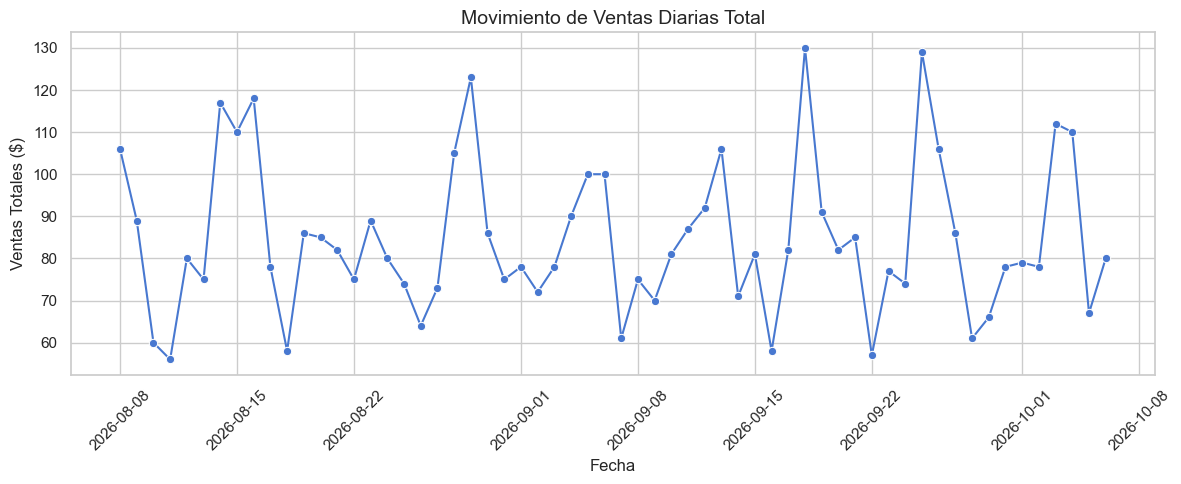

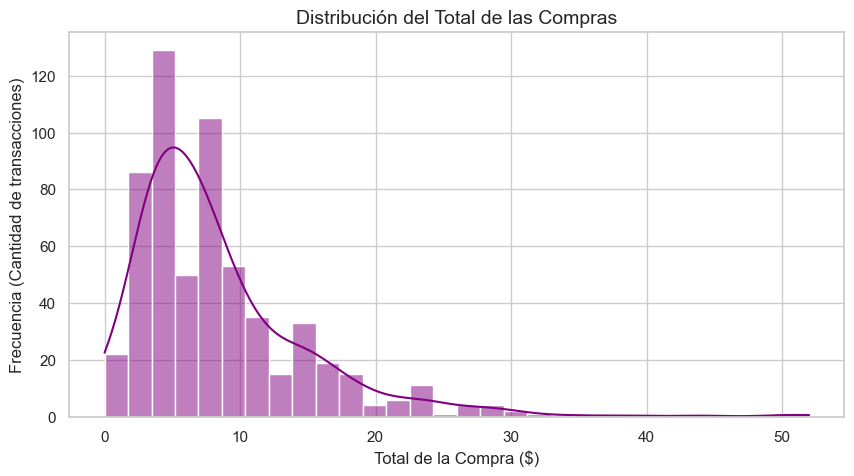

C:\Users\MSI KATANA\AppData\Local\Temp\ipykernel_1408\347969579.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, y='categoria', x='cantidad_vendida', estimator=sum, errorbar=None, palette='viridis')


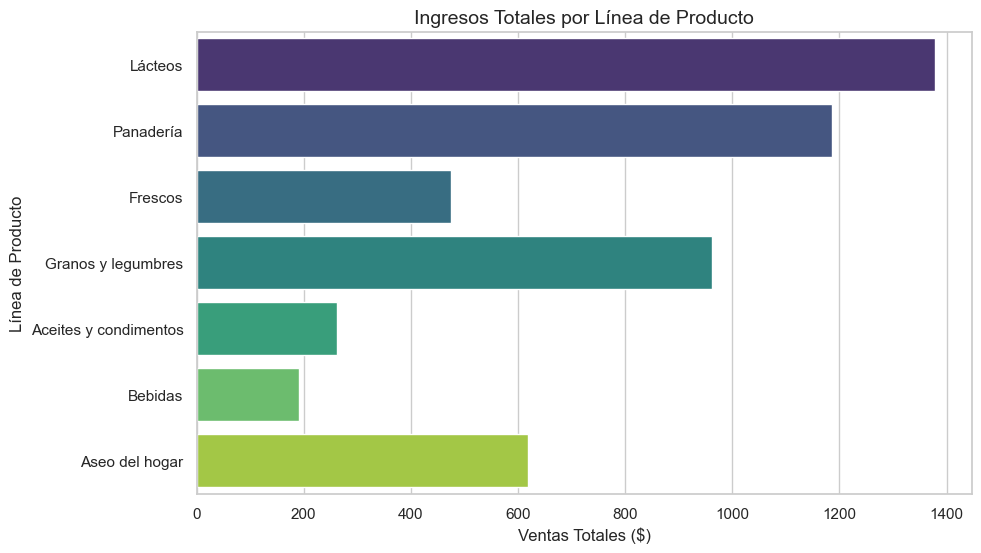

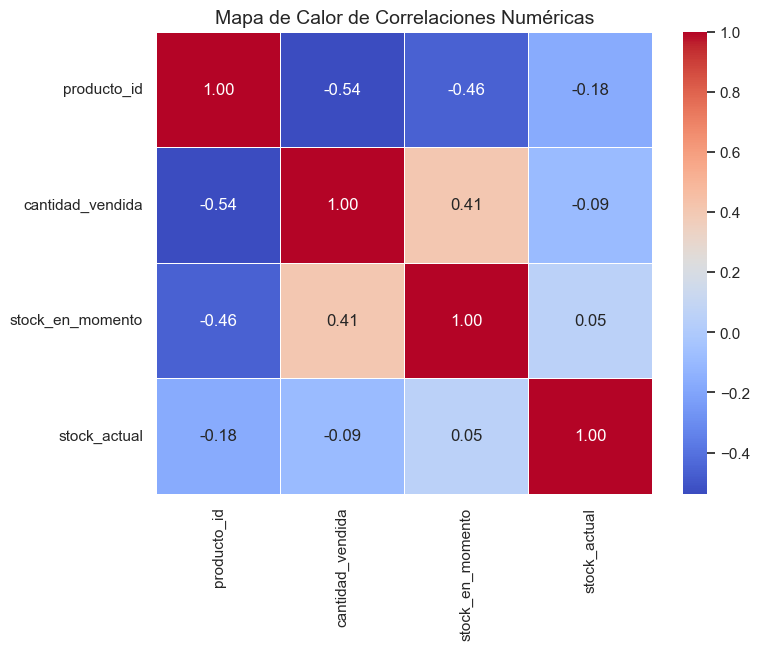

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar el estilo visual de los gráficos
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6) # Tamaño por defecto

# Convertir la columna 'Date' a formato datetime (ajusta el formato si es necesario)
df['fecha_venta'] = pd.to_datetime(df['fecha_venta'])

# Agrupar las ventas totales por fecha
ventas_diarias = df.groupby('fecha_venta')['cantidad_vendida'].sum().reset_index()

# Crear el gráfico de líneas
plt.figure(figsize=(12, 5))
sns.lineplot(data=ventas_diarias, x='fecha_venta', y='cantidad_vendida', marker='o', color='b')
plt.title('Movimiento de Ventas Diarias Total', fontsize=14)
plt.xlabel('Fecha')
plt.ylabel('Ventas Totales ($)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


plt.figure(figsize=(10, 5))
# Un histograma con la curva de densidad (KDE)
sns.histplot(df['cantidad_vendida'], bins=30, kde=True, color='purple')
plt.title('Distribución del Total de las Compras', fontsize=14)
plt.xlabel('Total de la Compra ($)')
plt.ylabel('Frecuencia (Cantidad de transacciones)')
plt.show()


plt.figure(figsize=(10, 6))
# Usamos estimator=sum para sumar el total de ventas por cada línea
sns.barplot(data=df, y='categoria', x='cantidad_vendida', estimator=sum, errorbar=None, palette='viridis')
plt.title('Ingresos Totales por Línea de Producto', fontsize=14)
plt.xlabel('Ventas Totales ($)')
plt.ylabel('Línea de Producto')
plt.show()


plt.figure(figsize=(8, 6))
# Seleccionamos solo las columnas numéricas para la correlación
columnas_numericas = df.select_dtypes(include=['float64', 'int64'])
matriz_correlacion = columnas_numericas.corr()

# Crear el mapa de calor
sns.heatmap(matriz_correlacion, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Mapa de Calor de Correlaciones Numéricas', fontsize=14)
plt.show()

### Paso 1.3 - Feature Engineering y Preparacion de Secuencias

Transformamos los datos crudos en caracteristicas utiles para el modelo de series temporales:

- **Conversion de fechas:** Parseamos echa_venta y echa_expiracion como datetime
- **dia_semana:** Numero del dia (0=Lunes, 6=Domingo) — captura patrones semanales
- **mes:** Mes del ano — captura estacionalidad mensual
- **es_fin_semana:** Indicador binario (1=Sabado/Domingo, 0=resto) — identifica picos de consumo
- **Ordenamiento cronologico:** Ordenamos por producto_id y echa_venta para garantizar el orden temporal correcto antes de crear secuencias de entrenamiento


In [ ]:
import pandas as pd
import numpy as np

# 1. Conversión de tipos de datos (Parsing)
df['fecha_venta'] = pd.to_datetime(df['fecha_venta'])
df['fecha_expiracion'] = pd.to_datetime(df['fecha_expiracion'])

# 2. Feature Engineering: Extracción de variables temporales
# Extraemos el día de la semana (0 = Lunes, 6 = Domingo)
df['dia_semana'] = df['fecha_venta'].dt.dayofweek

# Mes del año (para capturar estacionalidad)
df['mes'] = df['fecha_venta'].dt.month

# Indicador Booleano de Fin de Semana (1 si es sábado o domingo, 0 si no)
df['es_fin_semana'] = np.where(df['dia_semana'] >= 5, 1, 0)

# 3. Ordenamiento Crítico para Series Temporales
# Para predecir el futuro, el pasado debe estar en orden cronológico estricto
df = df.sort_values(by=['producto_id', 'fecha_venta']).reset_index(drop=True)

print("=== Datos tras Feature Engineering ===")
display(df[['producto_id', 'fecha_venta', 'dia_semana', 'es_fin_semana', 'cantidad_vendida']].head(7))

=== Datos tras Feature Engineering ===


,producto_id,fecha_venta,dia_semana,es_fin_semana,cantidad_vendida
0,1,2026-08-08,5,1,15
1,1,2026-08-09,6,1,18
2,1,2026-08-10,0,0,10
3,1,2026-08-11,1,0,0
4,1,2026-08-12,2,0,15
5,1,2026-08-13,3,0,15
6,1,2026-08-14,4,0,39
